In [1]:
pip install transformers sentence-transformers torch umap-learn wordcloud

  Using cached umap_learn-0.5.12-py3-none-any.whl.metadata (24 kB)
  Using cached wordcloud-1.9.6-cp313-cp313-win_amd64.whl.metadata (3.5 kB)
  Using cached safetensors-0.8.0-cp310-abi3-win_amd64.whl.metadata (4.2 kB)
  Using cached hf_xet-1.6.0-cp38-abi3-win_amd64.whl.metadata (4.9 kB)
  Using cached pynndescent-0.6.0-py3-none-any.whl.metadata (6.9 kB)
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   --------------------------- ------------ 8.7/12.6 MB 44.0 MB/s eta 0:00:01
   ---------------------------------------- 12.6/12.6 MB 39.0 MB/s eta 0:00:00
Using cached hf_xet-1.6.0-cp38-abi3-win_amd64.whl (4.0 MB)
   ---------------------------------------- 0.0/2.9 MB ? eta -:--:--
   ---------------------------------------- 2.9/2.9 MB 23.3 MB/s eta 0:00:00
   ---------------------------------------- 0.0/846.4 kB ? eta -:--:--
   --------------------------------------- 846.4/846.4 kB 15.7 MB/s eta 0:00:00
   ---------------------------------------- 0.0/740.6 kB ? et

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [67]:
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
import numpy as np
from wordcloud import WordCloud

In [23]:
df = pd.read_csv(
    "Online Retail Customer Feedback.csv",
    header=None,
    names=["Review"]
)

df.head()

,Review
0,"customer support was slightly disappointing, b..."
1,"the experience was decent, and the final bille..."
2,Superr 10 out of 10
3,wow nice option
4,"i found the buying process to be quite good, t..."


In [24]:
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

Rows: 965
Columns: 1


In [25]:
df.isnull().sum()

Review    0
dtype: int64

In [72]:
# Checking for and remove exact duplicate reviews

duplicates = df.duplicated().sum()

print(f"Duplicate reviews found: {duplicates}")

if duplicates > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print(f"Duplicate reviews removed: {duplicates}")

print(f"Rows remaining: {len(df)}")

Duplicate reviews found: 0
Rows remaining: 965


In [27]:
df.sample(10, random_state=42)

,Review
889,"the ordering experience felt decent, but commu..."
468,"the ordering experience felt inconsistent, tho..."
168,very very nice app verye asy
405,", customer support was slightly disappointing,..."
70,"using the app was average, though the delivery..."
139,", using the app was inconsistent, though the r..."
465,", i found the buying process to be satisfactor..."
456,", the ordering experience felt slightly disapp..."
88,"customer support was a bit confusing, but coup..."
302,the ordering experience felt slightly disappoi...


In [28]:
df["Length"] = df["Review"].str.split().str.len()

In [29]:
df["Length"].describe()

count    965.000000
mean      15.692228
std        3.693045
min        3.000000
25%       13.000000
50%       16.000000
75%       18.000000
max       28.000000
Name: Length, dtype: float64

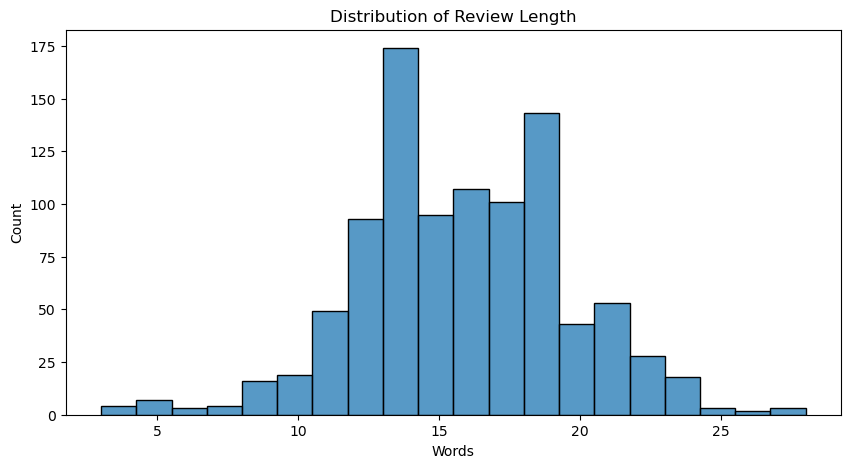

In [30]:
plt.figure(figsize=(10,5))

sns.histplot(df["Length"], bins=20)

plt.title("Distribution of Review Length")

plt.xlabel("Words")

plt.show()

In [33]:
import re

def clean_text(text):
    text = str(text).strip()
    text = re.sub(r"\s+", " ", text)
    return text

df["Clean_Review"] = df["Review"].apply(clean_text)

print("Text cleaning completed successfully.")
print("Missing Clean_Review values:", df["Clean_Review"].isna().sum())

Text cleaning completed successfully.
Missing Clean_Review values: 0


In [34]:
print(f"Average words: {df['Length'].mean():.2f}")

Average words: 15.69


In [35]:
df.loc[df["Length"].idxmax()]

Review          From my experience, from browsing to delivery,...
Length                                                         28
Clean_Review    From my experience, from browsing to delivery,...
Name: 612, dtype: object

In [36]:
df.loc[df["Length"].idxmin()]

Review          wow nice option
Length                        3
Clean_Review    wow nice option
Name: 3, dtype: object

Initial checks showed that there were no missing values or duplicate reviews in the dataset, so I only needed to do some basic text preprocessing. The reviews are also fairly short, which made them a good fit for the NLP based sentiment analysis approach I used.

**BERT (RoBERTa) Sentiment Analysis**

In [37]:
from transformers import pipeline
from tqdm.auto import tqdm

tqdm.pandas()

In [38]:
# Loading the pretrained RoBERTa sentiment model
sentiment_model = pipeline(
    "sentiment-analysis",
    model="cardiffnlp/twitter-roberta-base-sentiment-latest",
    tokenizer="cardiffnlp/twitter-roberta-base-sentiment-latest"
)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [39]:
test_reviews = [
    "Amazing customer service!",
    "The delivery was late and disappointing.",
    "The product is okay."
]

sentiment_model(test_reviews)

[{'label': 'positive', 'score': 0.971376895904541},
 {'label': 'negative', 'score': 0.9169977307319641},
 {'label': 'positive', 'score': 0.7576010823249817}]

In [40]:
reviews = df["Clean_Review"].tolist()

results = sentiment_model(
    reviews,
    batch_size=32,
    truncation=True
)

In [41]:
df["Sentiment"] = [result["label"].capitalize() for result in results]

df["Confidence"] = [result["score"] for result in results]

In [42]:
df.head()

,Review,Length,Clean_Review,Sentiment,Confidence
0,"customer support was slightly disappointing, b...",11,"customer support was slightly disappointing, b...",Negative,0.898648
1,"the experience was decent, and the final bille...",15,"the experience was decent, and the final bille...",Positive,0.851343
2,Superr 10 out of 10,5,Superr 10 out of 10,Positive,0.710208
3,wow nice option,3,wow nice option,Positive,0.932734
4,"i found the buying process to be quite good, t...",20,"i found the buying process to be quite good, t...",Positive,0.815214


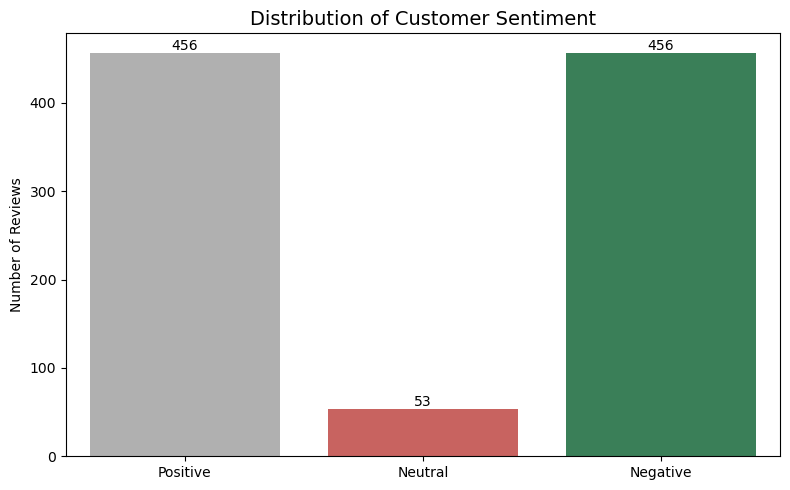

In [71]:
plt.figure(figsize=(8,5))

order = ["Positive", "Neutral", "Negative"]

ax = sns.countplot(
    data=df,
    x="Sentiment",
    order=order,
    hue="Sentiment",
    palette=["#2E8B57", "#B0B0B0", "#D9534F"],
    legend=False
)

plt.title("Distribution of Customer Sentiment", fontsize=14)
plt.xlabel("")
plt.ylabel("Number of Reviews")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

In [44]:
sentiment_summary = (
    df["Sentiment"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .rename("Percentage")
)

sentiment_summary

Sentiment
Negative    47.25
Positive    47.25
Neutral      5.49
Name: Percentage, dtype: float64

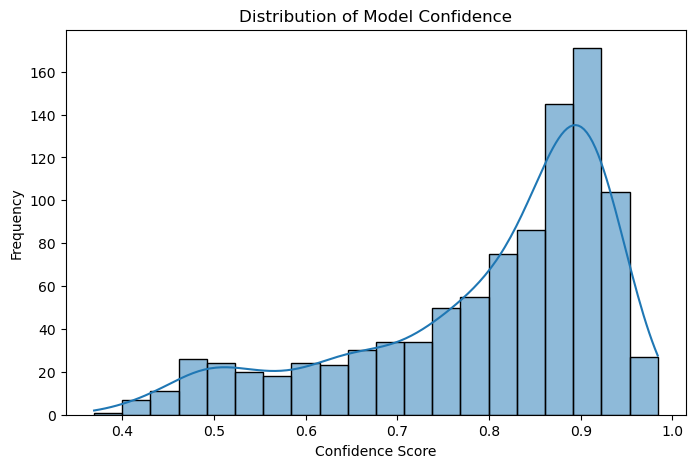

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(
    df["Confidence"],
    bins=20,
    kde=True
)

plt.title("Distribution of Model Prediction Scores")
plt.xlabel("Prediction Score")
plt.ylabel("Frequency")

plt.show()

In [46]:
confidence_summary = (
    df.groupby("Sentiment")["Confidence"]
      .mean()
      .sort_values(ascending=False)
      .round(3)
)

confidence_summary

Sentiment
Negative    0.824
Positive    0.808
Neutral     0.511
Name: Confidence, dtype: float64

In [47]:
df[df["Sentiment"]=="Positive"][["Review","Confidence"]].sample(10, random_state=42)

,Review,Confidence
781,", from browsing to delivery, the experience wa...",0.529330
100,", i found the buying process to be decent, and...",0.792420
704,"billing and payment were mostly fine, and the ...",0.534084
472,"customer support was quite good, though everyt...",0.912139
343,", i found the buying process to be mostly fine...",0.686721
443,", the checkout process seemed satisfactory, bu...",0.862875
382,", the experience was mostly fine, but billing ...",0.814379
237,"from browsing to delivery, the experience was ...",0.740035
840,", from browsing to delivery, the experience wa...",0.652010
81,", the experience was pleasant, but billing had...",0.908645


In [48]:
df[df["Sentiment"]=="Neutral"][["Review","Confidence"]].sample(53, random_state=42)

,Review,Confidence
344,"From my experience, billing and payment were i...",0.603888
732,"the checkout process seemed mostly fine, but c...",0.495089
890,"billing and payment were satisfactory, but cou...",0.476325
216,", using the app was pleasant, but coupon appli...",0.402319
764,my interaction with customer care was better t...,0.439542
69,the delivery experience turned out l...,0.453218
322,"billing and payment were mostly fine, but paym...",0.491343
935,", using the app was smooth, and refund process...",0.547214
52,"from browsing to delivery, the experience was ...",0.449620
617,"From my experience, my interaction with custom...",0.479135


In [49]:
df[df["Sentiment"]=="Negative"][["Review","Confidence"]].sample(5, random_state=42)

,Review,Confidence
799,", the checkout process seemed worse than expec...",0.727775
74,", i found the buying process to be average, an...",0.723043
729,"From my experience, billing and payment were i...",0.844233
444,they do too much telecalling and marketing,0.646028
314,"billing and payment were not very impressive, ...",0.915888


**Interpreting Model Prediction Scores**

When I looked at the prediction scores, the lower scores often appeared in reviews where the sentiment was more mixed or less direct. Some of these reviews used words such as “but” or “though,” which made me think the language was a little harder for the model to interpret.

So, it seems that more ambiguous wording was generally associated with lower model scores. I would not treat these scores as probabilities that the prediction is correct. Instead, they represent the model’s score for the class it predicted, so they are better viewed as an indication of how strongly the model leaned towards that prediction.

In [50]:
contrast_words = [
    "but",
    "although",
    "though",
    "however",
    "yet",
    "despite"
]

for word in contrast_words:
    count = df[df["Review"].str.contains(word, case=False, na=False)].shape[0]
    print(f"{word}: {count}")

but: 436
although: 0
though: 320
however: 0
yet: 0
despite: 0


In [51]:
for word in contrast_words:
    
    print(f"\n{word.upper()}")

    display(
        df[
            (df["Review"].str.contains(word, case=False, na=False))
        ]["Sentiment"].value_counts()
    )


BUT


Sentiment
Negative    232
Positive    171
Neutral      33
Name: count, dtype: int64


ALTHOUGH


Series([], Name: count, dtype: int64)


THOUGH


...

Series([], Name: count, dtype: int64)


YET


Series([], Name: count, dtype: int64)


DESPITE


Series([], Name: count, dtype: int64)

In [52]:
print("Most confident predictions")
display(
    df.nlargest(10, "Confidence")[["Review", "Sentiment", "Confidence"]]
)

print("Least confident predictions")
display(
    df.nsmallest(10, "Confidence")[["Review", "Sentiment", "Confidence"]]
)

Most confident predictions


,Review,Sentiment,Confidence
506,"one of the better web app ,nicee experience",Positive,0.983997
644,The product quality is actually better than I ...,Positive,0.981580
155,"its is indeed good,worth recommending",Positive,0.978589
575,"Overall a good experience, would probably orde...",Positive,0.977967
571,"Website is attractive, very nicee,I think its ...",Positive,0.975615
751,Good liked it next purchase...,Positive,0.974623
152,"Good good good ,very good",Positive,0.973159
9,The experience was good,Positive,0.972202
311,I thought very nice experiecne ...,Positive,0.972162
226,"Verrry nicee experince, will buy again on weekend",Positive,0.970513


Least confident predictions


,Review,Sentiment,Confidence
22,", from browsing to delivery, the experience wa...",Neutral,0.369177
111,", the checkout process seemed decent, though t...",Neutral,0.402257
216,", using the app was pleasant, but coupon appli...",Neutral,0.402319
384,", billing and payment were pleasant, but coupo...",Positive,0.413840
936,"the ordering experience felt satisfactory, but...",Neutral,0.413956
145,", using the app was quite good, but coupon app...",Neutral,0.416491
964,the ordering experience felt better than expec...,Neutral,0.418817
723,", customer support was smooth, but coupon appl...",Negative,0.419683
780,"the checkout process seemed quite good, but co...",Positive,0.432719
134,", the delivery experience turned out ...",Positive,0.435304


*The model seems to be very confident when the sentiment is obvious, especially when reviews use words like “good,” “better,” or “nice.” But once people start mixing opinions with words like “but” or “though,” the model becomes less certain, which makes sense because now it's dealing with two sides of the story*

*What surprised me most is that our original idea that reviews with “but” would mostly be neutral was pretty much wrong. Only 8% were neutral, while 53% were negative and 39% were positive. Reviews containing “though” showed a similar pattern, with only 5% being neutral. So I'm starting to think that words like “but” and “though” aren't really signals of neutrality at all they're more like little warning signs that the sentence contains competing feelings, making the language harder for the model to interpret*

**Semantic Representation Using Sentence BERT**


In [53]:
from sentence_transformers import SentenceTransformer

embedding_model = SentenceTransformer("all-MiniLM-L6-v2")

embeddings = embedding_model.encode(
    df["Clean_Review"].tolist(),
    show_progress_bar=True,
    batch_size=32
)

print("Embedding shape:", embeddings.shape)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/31 [00:00<?, ?it/s]

Embedding shape: (965, 384)


In [54]:
sentiment_mapping = {
    "Negative": -1,
    "Neutral": 0,
    "Positive": 1
}

df["Sentiment_Score"] = df["Sentiment"].map(sentiment_mapping)

In [55]:
import umap.umap_ as umap

umap_model = umap.UMAP(
    n_neighbors=15,
    n_components=2,
    metric="cosine",
    random_state=42
)

embedding_2d = umap_model.fit_transform(embeddings)

df["UMAP_1"] = embedding_2d[:, 0]
df["UMAP_2"] = embedding_2d[:, 1]

c:\Users\user\anaconda3\envs\retail-analytics\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


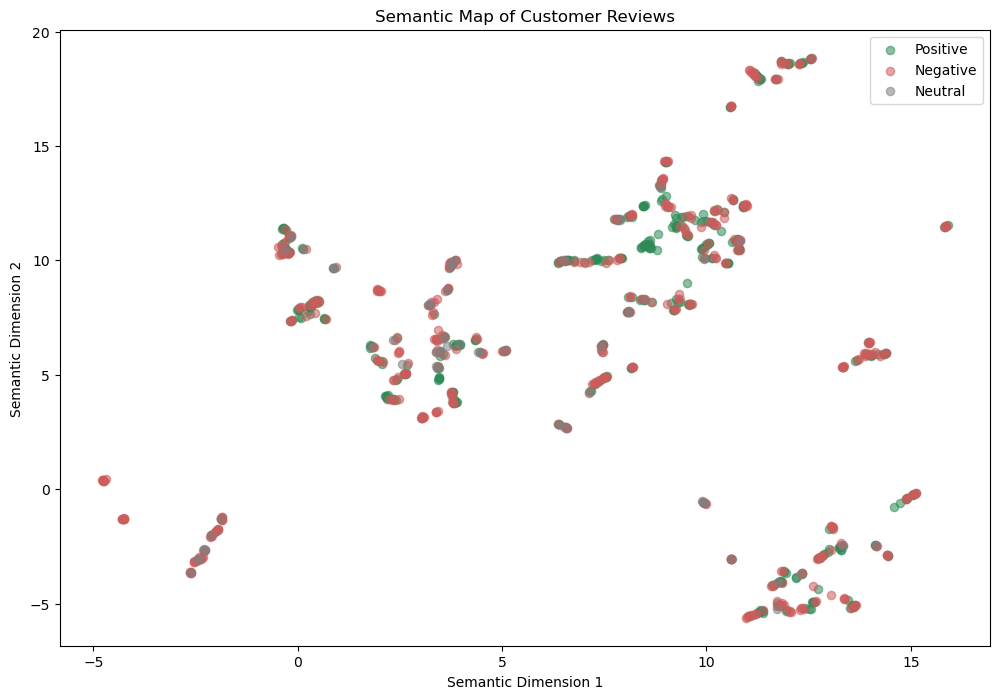

In [56]:
plt.figure(figsize=(12, 8))

colors = {
    "Positive": "seagreen",
    "Negative": "indianred",
    "Neutral": "gray"
}

for sentiment, color in colors.items():

    subset = df[df["Sentiment"] == sentiment]

    plt.scatter(
        subset["UMAP_1"],
        subset["UMAP_2"],
        label=sentiment,
        alpha=0.55,
        s=35,
        c=color
    )

plt.title("Semantic Map of Customer Reviews")
plt.xlabel("Semantic Dimension 1")
plt.ylabel("Semantic Dimension 2")
plt.legend()

plt.show()

In [57]:
# Separate reviews by sentiment
positive_reviews = df.loc[
    df["Sentiment"] == "Positive", "Clean_Review"
]

negative_reviews = df.loc[
    df["Sentiment"] == "Negative", "Clean_Review"
]

neutral_reviews = df.loc[
    df["Sentiment"] == "Neutral", "Clean_Review"
]

print("Positive reviews:", len(positive_reviews))
print("Negative reviews:", len(negative_reviews))
print("Neutral reviews:", len(neutral_reviews))

Positive reviews: 456
Negative reviews: 456
Neutral reviews: 53


In [58]:
from sklearn.feature_extraction.text import TfidfVectorizer

def extract_keywords(reviews, n=15):

    vectorizer = TfidfVectorizer(
        stop_words="english",
        ngram_range=(1, 2),
        min_df=3,
        max_features=3000
    )

    X = vectorizer.fit_transform(reviews)

    scores = np.asarray(X.mean(axis=0)).flatten()

    terms = vectorizer.get_feature_names_out()

    results = pd.DataFrame({
        "Term": terms,
        "TF_IDF": scores
    })

    return results.sort_values(
        "TF_IDF",
        ascending=False
    ).head(n)

In [61]:
positive_keywords = extract_keywords(
    positive_reviews,
    n=20
)

positive_keywords

,Term,TF_IDF
118,experience,0.072281
80,delivery,0.045426
288,support,0.044781
43,checkout,0.043877
57,customer,0.042872
5,app,0.041310
221,process,0.040784
150,fine,0.040492
164,good,0.039770
17,better,0.036772


In [62]:
negative_keywords = extract_keywords(
    negative_reviews,
    n=20
)

negative_keywords

,Term,TF_IDF
128,experience,0.066728
264,slightly,0.046263
90,delivery,0.044190
5,app,0.041808
282,support,0.041558
78,customer,0.041255
54,checkout,0.041059
216,payment,0.039830
33,billing,0.036755
92,delivery experience,0.036232


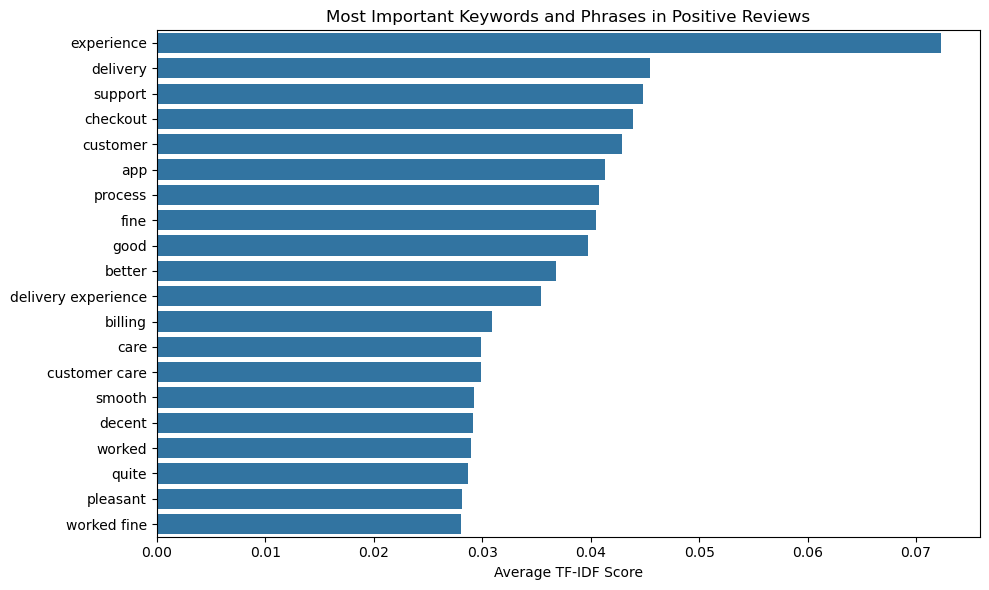

In [63]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=positive_keywords,
    x="TF_IDF",
    y="Term"
)

plt.title("Most Important Keywords and Phrases in Positive Reviews")
plt.xlabel("Average TF-IDF Score")
plt.ylabel("")

plt.tight_layout()
plt.show()

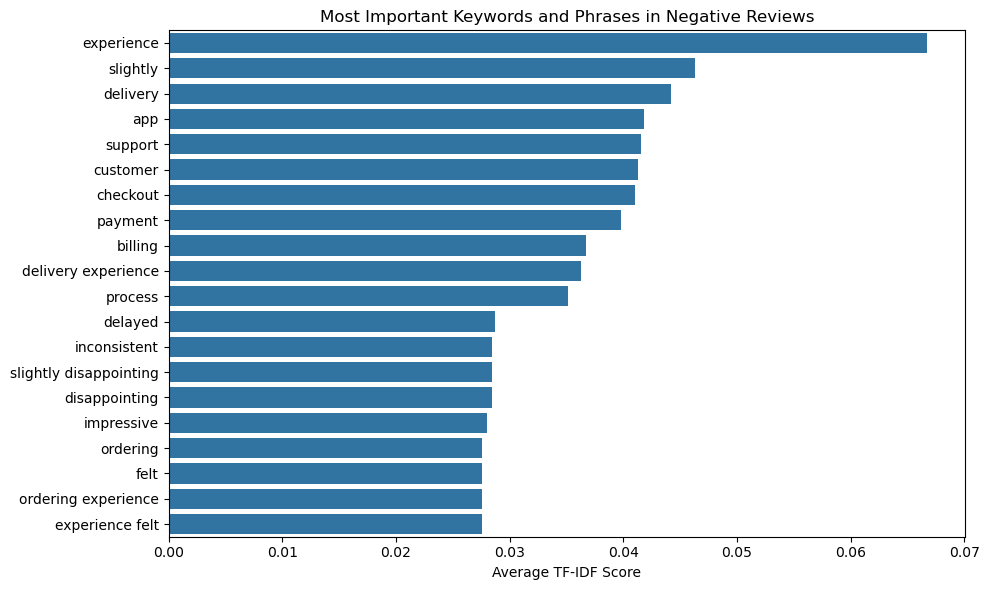

In [64]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=negative_keywords,
    x="TF_IDF",
    y="Term"
)

plt.title("Most Important Keywords and Phrases in Negative Reviews")
plt.xlabel("Average TF-IDF Score")
plt.ylabel("")

plt.tight_layout()
plt.show()

In [65]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

custom_stopwords = set(ENGLISH_STOP_WORDS)

# Generic words that are not useful for identifying business themes
custom_stopwords.update([
    "experience",
    "experiences",
    "customer",
    "customers",
    "thing",
    "things",
    "overall",
    "really",
    "quite",
    "mostly",
    "fairly",
    "slightly",
    "little",
    "bit",
    "much",
    "many",
    "everything",
    "something",
    "anything",
    "nothing",
    "though",
    "although",
    "but",
    "was",
    "were",
    "felt",
    "seemed",
    "found",
    "said",
    "got",
    "get",
    "getting",
    "would",
    "could",
    "still",
    "also",
    "one",
    "two",
    "well",
    "just",
    "like",
    "the",
    "good"
])

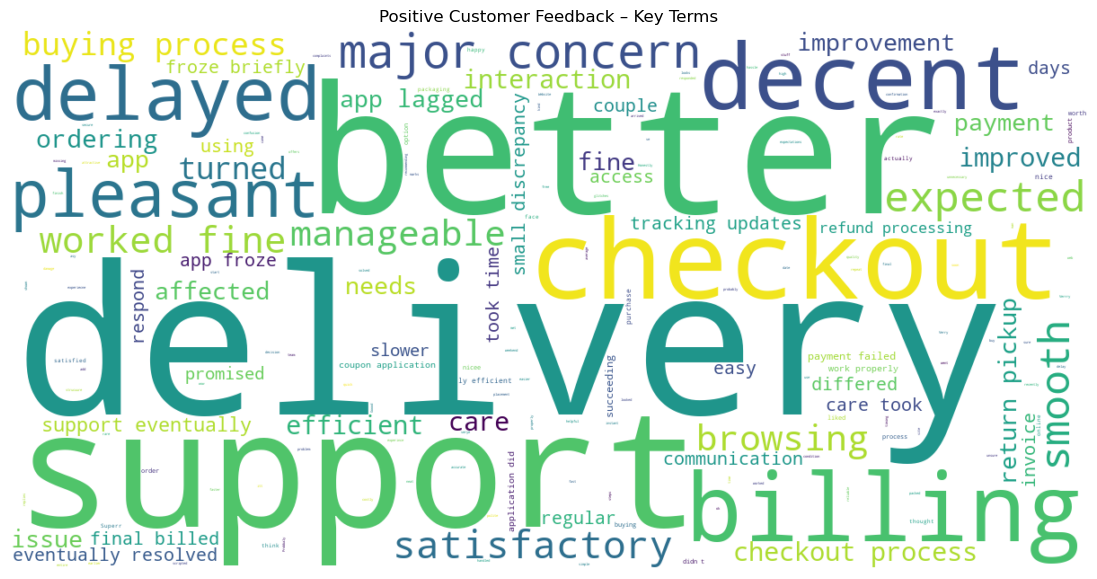

In [68]:
positive_text = " ".join(positive_reviews)

positive_wc = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    stopwords=custom_stopwords,
    collocations=True
).generate(positive_text)

plt.figure(figsize=(14, 7))
plt.imshow(positive_wc, interpolation="bilinear")
plt.axis("off")
plt.title("Positive Customer Feedback – Key Terms")
plt.show()

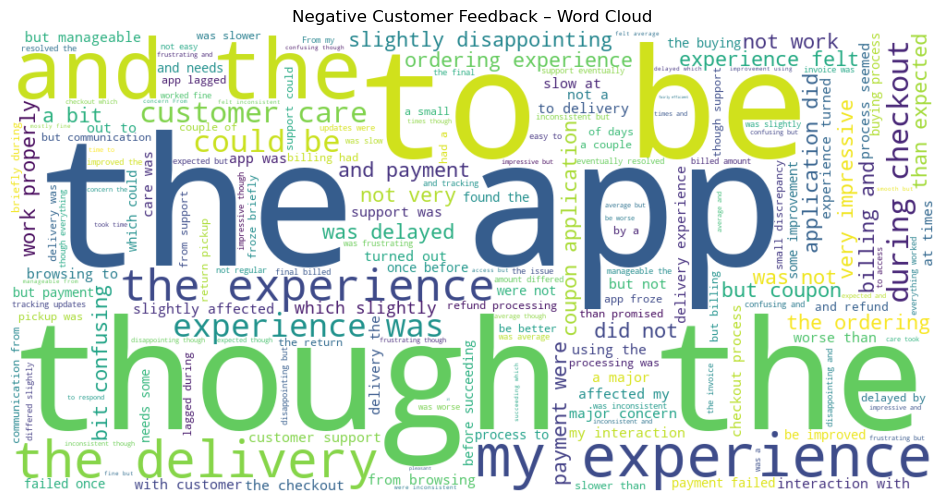

In [69]:
negative_text = " ".join(negative_reviews)

negative_wc = WordCloud(
    width=1000,
    height=500,
    background_color="white",
    stopwords="english"
).generate(negative_text)

plt.figure(figsize=(12, 6))
plt.imshow(negative_wc, interpolation="bilinear")
plt.axis("off")
plt.title("Negative Customer Feedback – Word Cloud")
plt.show()

**Business Interpretation**

When I looked through the sentiment and keyword results, delivery came up as a recurring theme in the customer feedback. Some positive reviews mentioned satisfactory delivery experiences, while some negative reviews also referred to problems with delivery.

To me, this suggests that delivery is an area customers talk about in the feedback, both positively and negatively. However, I would be careful not to take this as evidence that delivery performance is causing customer sentiment. The analysis shows an observed relationship in the feedback, but it does not establish causation.